# Hands-on 12: Dataset Sintetis untuk Klasifikasi dan Anomaly Detection

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 4.

Dataset smart room 15 hari @ 10 menit dengan label normal/warning/fault dan kolom
`is_anomaly`: `data/synthetic/room_classification_dataset.csv` (2050 normal, 80 warning,
30 fault).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Dataset

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_room_classification_dataset.py"], capture_output=True, text=True)
print(r.stdout)

Dataset klasifikasi/anomali disimpan ke: data/synthetic/room_classification_dataset.csv
status_label
normal     2050
warning      80
fault        30
Name: count, dtype: int64
            timestamp device_id  ...  status_label  is_anomaly
0 2026-01-01 00:00:00    room01  ...        normal           0
1 2026-01-01 00:10:00    room01  ...        normal           0
2 2026-01-01 00:20:00    room01  ...        normal           0
3 2026-01-01 00:30:00    room01  ...        normal           0
4 2026-01-01 00:40:00    room01  ...        normal           0

[5 rows x 8 columns]



## 2. Visualisasi Sebaran Label

[SUKSES] outputs/figures/room_classification_scatter.png



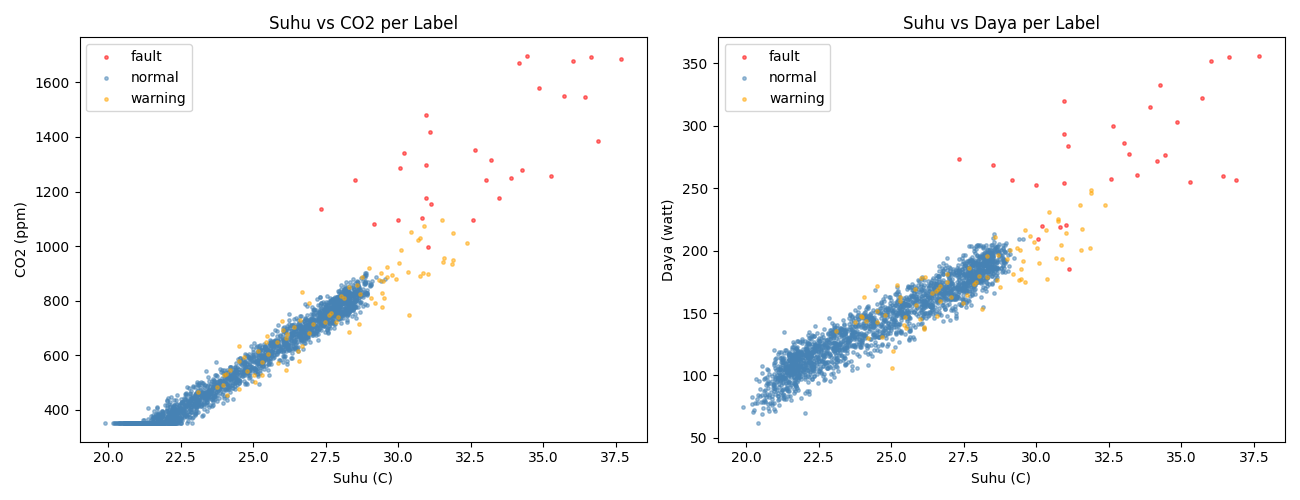

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_classification_dataset.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/room_classification_scatter.png")

## Penutup

Kelas warning/fault terpisah jelas pada ruang suhu-CO2-daya. Dataset ini menjadi bahan
Hands-on 20 (dataset klasifikasi), Hands-on 24 (klasifikasi status perangkat), dan
Hands-on 22 Bab 9 (Isolation Forest).

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 12 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 4. Mengapa dataset ini berguna?

Dataset ini bisa langsung dipakai untuk:
- klasifikasi 3 kelas: normal, warning, fault

binary anomaly detection: is_anomaly
visualisasi sebaran kelas
uji imbalance
latihan model dasar seperti Logistic Regression, Random Forest, dan
Isolation Forest di bab berikutnya.

### 5. Cek keseimbangan label

Buat file scripts/check_label_distribution.py:
from pathlib import Path
import pandas as pd
DATA_PATH = Path("data/synthetic/room_classification_dataset.csv")
df = pd.read_csv(DATA_PATH)
print("Distribusi status_label:")
print(df["status_label"].value_counts())
print("\nDistribusi is_anomaly:")
print(df["is_anomaly"].value_counts())

Ini penting karena di IoT, kejadian abnormal memang sering lebih sedikit daripada
kondisi normal. Itu sebabnya label sintetis sangat membantu untuk latihan awal.

## Jawaban dari data: Cek keseimbangan label (Hands-on 12): jawaban dari data

In [4]:
import pandas as pd
df = pd.read_csv("data/synthetic/room_classification_dataset.csv")
print(df["status_label"].value_counts())
print((df["status_label"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")
print(df["is_anomaly"].value_counts())
print("Kejadian abnormal (warning/fault) lebih sedikit dari normal:", (df.status_label != "normal").sum() < (df.status_label == "normal").sum())

status_label
normal     2050
warning      80
fault        30
Name: count, dtype: int64
status_label
normal     94.9 %
warning     3.7 %
fault       1.4 %
Name: proportion, dtype: object
is_anomaly
0    2050
1     110
Name: count, dtype: int64
Kejadian abnormal (warning/fault) lebih sedikit dari normal: True
